# 📊 Where Does the Money Sit in Crypto? A Look at Market Concentration and Liquidity

**Project Overview**

Crypto is often described as a few giants and a long tail of small coins. This project tests that idea with data: how much of the market's value and daily trading activity sits in a handful of coins?

I pulled live data on the top 250 cryptocurrencies from the CoinGecko API, stored it in a SQLite database, and used SQL and Python to measure market share and trading volume concentration.

**Key finding:** The 10 largest coins hold **89.6%** of the market cap among the top 250, and the 10 most-traded coins account for **92.0%** of trading volume.


***Key Analytical Methods & Tech Stack***


* **Tools**: Python (pandas, requests, matplotlib, seaborn), SQL, (sqlite/SQLAlchemy), Google Colab.
* **Data Sources**: CoinGecko API, top 250 coins by market cap (price, market cap, 24-hour volume, daily range). Results shown are from a snapshot taken 2026-11-25 08:43 UTC. Project started October 2026. Re-running the notebook pulls live data, so the numbers will change.


***Advanced SQL Techniques***:

* INNER JOIN & ORDER BY: Evaluates core asset tiering by matching curated utility categories against live market capitalizations.

* LEFT JOIN, GROUP BY, & HAVING: Performs market segmentation to filter and isolate high-value asset tiers exceeding specific price benchmarks.

* **Window Functions**: (RANK(), DENSE_RANK()): Establishes global liquidity leaderboards to quantify trading volume concentration.







 **Core Business Insights**


1. Asset Valuation & Infrastructure Dominance: Capital concentrates heavily on foundational blockchain utility and primary stores of value rather than peripheral token use cases.


2. High-Value Segmentation: Premium pricing tiers are tightly restricted to a select subset of structured market categories, filtering out long-tail, low-value speculative assets.

3. Liquidity Skew: Global market liquidity exhibits severe concentration, with a small fraction of blue-chip tokens capturing the vast majority of active trading volume.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from sqlalchemy import create_engine

In [2]:
def get_top_coins(limit=250):
    # fetch the top coins by market cap from CoinGecko
    url = "https://api.coingecko.com/api/v3/coins/markets"
    params = {
        "vs_currency": "usd",
        "order": "market_cap_desc",
        "per_page": limit,
        "page": 1,
    }
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()  # stops with a clear error if the API fails
    return pd.DataFrame(response.json())


columns = [
    "id", "symbol", "name", "current_price", "market_cap",
    "market_cap_rank", "total_volume", "high_24h", "low_24h",
    "price_change_percentage_24h",
]

df_crypto = get_top_coins()[columns]

# Drop coins with missing market cap or volume so they don't skew results
df_crypto = df_crypto.dropna(subset=["market_cap", "total_volume"])

# record when the snapshot was taken
df_crypto["fetched_at"] = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d %H:%M UTC")

# Save to SQLite
engine = create_engine("sqlite:///crypto_project.db")
df_crypto.to_sql("crypto_market", engine, if_exists="replace", index=False)

print(f"Saved {len(df_crypto)} coins | Snapshot: {df_crypto['fetched_at'].iloc[0]}")
df_crypto.head()

Saved 250 coins | Snapshot: 2026-11-25 08:43 UTC


,id,symbol,name,current_price,market_cap,market_cap_rank,total_volume,high_24h,low_24h,price_change_percentage_24h,fetched_at
0,bitcoin,btc,Bitcoin,59206.000000,1191051785107,1,2.998120e+10,60524.000000,58601.000000,-1.57104,2026-11-25 08:43 UTC
1,ethereum,eth,Ethereum,1649.350000,201634477417,2,1.029826e+10,1703.650000,1636.150000,-2.61027,2026-11-25 08:43 UTC
2,tether,usdt,Tether,0.998874,174641597268,3,4.578338e+10,0.999319,0.998631,-0.02916,2026-11-25 08:43 UTC
3,binancecoin,bnb,BNB,542.280000,71315713658,4,4.510017e+08,553.180000,537.580000,-1.42168,2026-11-25 08:43 UTC
4,usd-coin,usdc,USDC,0.999525,69002155409,5,1.329286e+10,0.999721,0.999212,-0.01054,2026-11-25 08:43 UTC


 Quick checks: bottom, and random rows, data types, and nulls.

In [3]:
df_crypto.tail()

,id,symbol,name,current_price,market_cap,market_cap_rank,total_volume,high_24h,low_24h,price_change_percentage_24h,fetched_at
245,edgex,edge,edgeX,0.262308,91807719,246,1955990.0,0.264742,0.253277,-0.06519,2026-11-25 08:43 UTC
246,genius-3,genius,Genius,0.273062,91578718,247,2146942.0,0.290869,0.272785,-5.46945,2026-11-25 08:43 UTC
247,aerodrome-finance,aero,Aerodrome Finance,0.385800,90639358,248,16247671.0,0.414632,0.385077,-6.67658,2026-11-25 08:43 UTC
248,railgun,rail,Railgun,1.500000,89731495,249,51065.0,1.640000,1.470000,-5.44472,2026-11-25 08:43 UTC
249,frax-usd,frxusd,Frax USD,0.999898,89569807,250,5072640.0,1.001000,0.999601,-0.02441,2026-11-25 08:43 UTC


In [4]:
df_crypto.sample(5)

,id,symbol,name,current_price,market_cap,market_cap_rank,total_volume,high_24h,low_24h,price_change_percentage_24h,fetched_at
162,compound-governance-token,comp,Compound,17.290000,172916741,163,9596150.0,17.560000,17.070000,-0.97540,2026-11-25 08:43 UTC
144,frax,frax,Legacy Frax Dollar,0.993233,217589182,145,196459.0,0.995280,0.992542,-0.06314,2026-11-25 08:43 UTC
243,chiliz,chz,Chiliz,0.008738,92874696,244,12512255.0,0.008945,0.008577,-2.13530,2026-11-25 08:43 UTC
65,bitget-token,bgb,Bitget Token,1.530000,1071310353,66,7418088.0,1.560000,1.530000,-1.53999,2026-11-25 08:43 UTC
72,kucoin-shares,kcs,KuCoin,5.870000,819438334,73,3441107.0,5.990000,5.810000,-1.59490,2026-11-25 08:43 UTC


In [5]:
df_crypto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           250 non-null    object 
 1   symbol                       250 non-null    object 
 2   name                         250 non-null    object 
 3   current_price                250 non-null    float64
 4   market_cap                   250 non-null    int64  
 5   market_cap_rank              250 non-null    int64  
 6   total_volume                 250 non-null    float64
 7   high_24h                     250 non-null    float64
 8   low_24h                      250 non-null    float64
 9   price_change_percentage_24h  246 non-null    float64
 10  fetched_at                   250 non-null    object 
dtypes: float64(5), int64(2), object(4)
memory usage: 21.6+ KB


In [6]:
import time

# Categories in priority order. Each coin gets the FIRST one it matches,
# so no coin is counted twice.
categories = {
    "stablecoins": "Stablecoins",
    "real-world-assets-rwa": "Real-World Assets",
    "exchange-based-tokens": "Exchange Tokens",
    "privacy-coins": "Privacy Coins",
    "meme-token": "Meme Coins",
    "artificial-intelligence": "AI",
    "layer-1": "Layer 1",
    "decentralized-finance-defi": "DeFi",
}


def get_category_coin_ids(category_id, retries=3):
    # fetch the coin ids for one category, retrying if we get rate-limited
    url = "https://api.coingecko.com/api/v3/coins/markets"
    params = {
        "vs_currency": "usd",
        "category": category_id,
        "order": "market_cap_desc",
        "per_page": 250,
        "page": 1,
    }

    for attempt in range(retries):
        response = requests.get(url, params=params, timeout=30)

        if response.status_code == 429:
            wait = 30 * (attempt + 1)
            print(f"Rate limited on {category_id}. Waiting {wait} seconds...")
            time.sleep(wait)
            continue

        response.raise_for_status()
        return [coin["id"] for coin in response.json()]

    raise requests.RequestException(f"Still rate limited after {retries} tries")


rows = []
already_assigned = set()

for category_id, label in categories.items():
    try:
        coin_ids = get_category_coin_ids(category_id)
    except requests.RequestException as error:
        print(f"Skipped {label}: {error}")
        continue

    for coin_id in coin_ids:
        if coin_id not in already_assigned:
            rows.append({"id": coin_id, "category": label})
            already_assigned.add(coin_id)

    print(f"Done: {label}")
    time.sleep(15)  # longer pause between categories

# Keep only coins that are in our top 250
df_categories = pd.DataFrame(rows)
df_categories = df_categories[df_categories["id"].isin(df_crypto["id"])]

# Save to the database
df_categories.to_sql("crypto_categories", engine, if_exists="replace", index=False)

print(f"{len(df_categories)} of {len(df_crypto)} coins categorized")
df_categories["category"].value_counts()

Done: Stablecoins
Done: Real-World Assets
Done: Exchange Tokens
Done: Privacy Coins
Done: Meme Coins
Done: AI
Done: Layer 1
Done: DeFi
210 of 250 coins categorized


,count
category,
Real-World Assets,43
Layer 1,37
Stablecoins,36
Exchange Tokens,28
DeFi,28
AI,22
Meme Coins,13
Privacy Coins,3


***Business Question:*** How do the market prices and global rankings of our core tracked assets compare when matched with their designated blockchain utility categories?

In [7]:


# Write your SQL query combining both tables
query = """
SELECT
    c.name,
    c.symbol,
    c.current_price,
    c.market_cap_rank,
    cat.category
FROM crypto_market c
INNER JOIN crypto_categories cat ON c.id = cat.id
ORDER BY c.market_cap_rank ASC;
"""

# Run the query and display it as a clean table
df_result = pd.read_sql(query, engine)
df_result

,name,symbol,current_price,market_cap_rank,category
0,Bitcoin,btc,59206.000000,1,Layer 1
1,Ethereum,eth,1649.350000,2,Layer 1
2,Tether,usdt,0.998874,3,Stablecoins
3,BNB,bnb,542.280000,4,Exchange Tokens
4,USDC,usdc,0.999525,5,Stablecoins
...,...,...,...,...,...
205,Chiliz,chz,0.008738,244,Layer 1
206,AIOZ Network,aioz,0.071336,245,AI
207,edgeX,edge,0.262308,246,Exchange Tokens
208,Aerodrome Finance,aero,0.385800,248,Exchange Tokens


Business Question: Across the global market, which specific asset categories maintain an average token price exceeding $50, and how many coins make up each group?

In [8]:
query_2 = """
SELECT
    COALESCE(cat.category, 'Uncategorized') AS asset_category,
    AVG(c.current_price) AS avg_price,
    COUNT(c.id) AS coin_count
FROM crypto_market c
LEFT JOIN crypto_categories cat ON c.id = cat.id
GROUP BY asset_category
HAVING AVG(c.current_price) > 50
ORDER BY avg_price DESC;
"""

print("--- Query 2: High-Value Market Segment Filtering ---")
df_result2 = pd.read_sql(query_2, engine)
display(df_result2)

--- Query 2: High-Value Market Segment Filtering ---


,asset_category,avg_price,coin_count
0,Layer 1,1653.494493,37
1,Privacy Coins,416.350000,3
2,Real-World Assets,213.221685,43


Business Question: Which cryptocurrencies are dominating global market liquidity based on 24-hour trading volume, and what are their exact standings?

In [9]:
query_3 = """
SELECT
    name,
    symbol,
    total_volume,
    RANK() OVER (ORDER BY total_volume DESC) AS volume_rank,
    DENSE_RANK() OVER (ORDER BY total_volume DESC) AS volume_dense_rank
FROM crypto_market;
"""

print("--- Query 3: Liquidity Concentration & Market Dominance ---")
df_result3 = pd.read_sql(query_3, engine)
display(df_result3)

--- Query 3: Liquidity Concentration & Market Dominance ---


,name,symbol,total_volume,volume_rank,volume_dense_rank
0,Tether,usdt,4.578338e+10,1,1
1,Bitcoin,btc,2.998120e+10,2,2
2,USDC,usdc,1.329286e+10,3,3
3,Ethereum,eth,1.029826e+10,4,4
4,Solana,sol,2.624680e+09,5,5
...,...,...,...,...,...
245,Tradable LatAm Middle-Market Lender SSTL,pc0000085,0.000000e+00,230,230
246,Nest BlackOpal LiquidStone II Vault,nopal,0.000000e+00,230,230
247,Securitize Tokenized AAA CLO Fund,stac,0.000000e+00,230,230
248,Tradable NA Third Party Online Merchant SSTN,pc0000015,0.000000e+00,230,230


### 📈 New Analytics: Top Performing Cryptocurrencies (24h Price Change)
To see which assets are performing best today, we will write a SQL query to sort our database by the 24-hour price change percentage in descending order.

In [10]:
# Query the top 10 performing assets today sorted by our newly added column
query_performance = """
SELECT
    name,
    symbol,
    current_price,
    price_change_percentage_24h
FROM crypto_market
WHERE price_change_percentage_24h IS NOT NULL
ORDER BY price_change_percentage_24h DESC
LIMIT 10;
"""

df_performance = pd.read_sql(query_performance, engine)
display(df_performance)

,name,symbol,current_price,price_change_percentage_24h
0,Bitway,btw,0.890960,27.42728
1,Pharos,pros,0.720475,20.52149
2,Sky,sky,0.041025,5.19219
3,SoSoValue,soso,0.288071,3.38708
4,Terra Luna Classic,lunc,0.000046,3.11360
5,o1.exchange,o,0.587375,2.58975
6,Ozone Chain,ozo,0.238674,2.50464
7,​​Stable,stable,0.023766,2.50325
8,Monero,xmr,506.580000,1.93496
9,Derive,drv,0.332534,1.23201


# ***Visualizations***

**Chart 1**: Trading Volume Leaderboard (Liquidity Concentration)

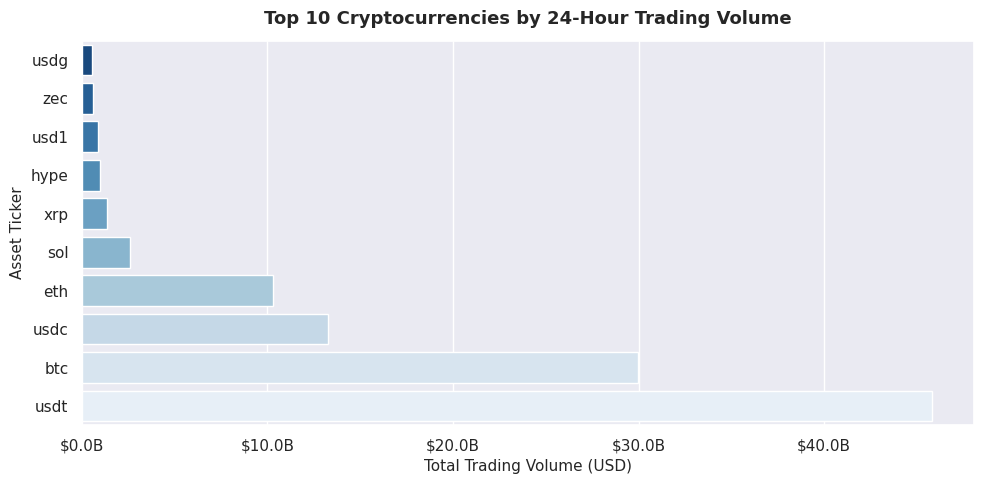

In [17]:
# Set the visual style
sns.set_theme(style="darkgrid")
plt.figure(figsize=(10, 5))

# Grab the top 10 coins by trading volume
df_top_volume = df_result3.head(10).sort_values(
    by="total_volume", ascending=True
)

# Create the horizontal bar chart
ax = sns.barplot(
    x="total_volume",
    y="symbol",
    data=df_top_volume,
    hue= "symbol",
    palette="Blues_r"
)

# Format titles and labels
plt.title(
    "Top 10 Cryptocurrencies by 24-Hour Trading Volume",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Total Trading Volume (USD)", fontsize=11)
plt.ylabel("Asset Ticker", fontsize=11)

# Format x-axis values in Billions ($B)
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: f"${x*1e-9:,.1f}B")
)

plt.tight_layout()
plt.show()

This horizontal bar chart visualizes the results of the window function query (RANK() and DENSE_RANK()), illustrating global market liquidity concentration. It highlights how a tiny fraction of blue-chip assets captures the vast majority of active 24-hour trading volume, demonstrating a steep liquidity drop-off outside the market leaders.

**Chart 2**: Average Price by Category (HAVING Filter Results)

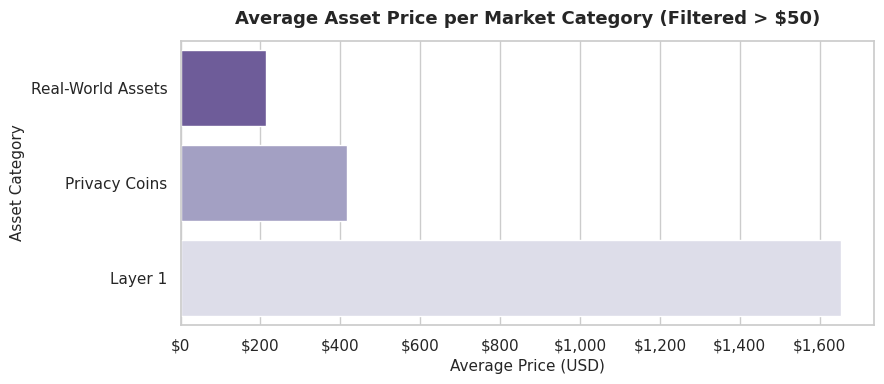

In [15]:
plt.figure(figsize=(9, 4))

# Sort category results by average price
df_sorted_cat = df_result2.sort_values(by="avg_price", ascending=True)

# Create a bar chart for category averages
ax2 = sns.barplot(
    x="avg_price",
    y="asset_category",
    data=df_sorted_cat,
    hue="asset_category",
    palette="Purples_r"
)

# Format titles and labels
plt.title(
    "Average Asset Price per Market Category (Filtered > $50)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Average Price (USD)", fontsize=11)
plt.ylabel("Asset Category", fontsize=11)

# Format x-axis values with currency
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"${x:,.0f}"))

plt.tight_layout()
plt.show()

### 📈 Addressing Scale Issues: Log Scale Line Chart
Bitcoin's price is thousands of times higher than most coins, so a normal axis would flatten everything else. Plotting the 15 largest coins on a logarithmic scale keeps them all visible.


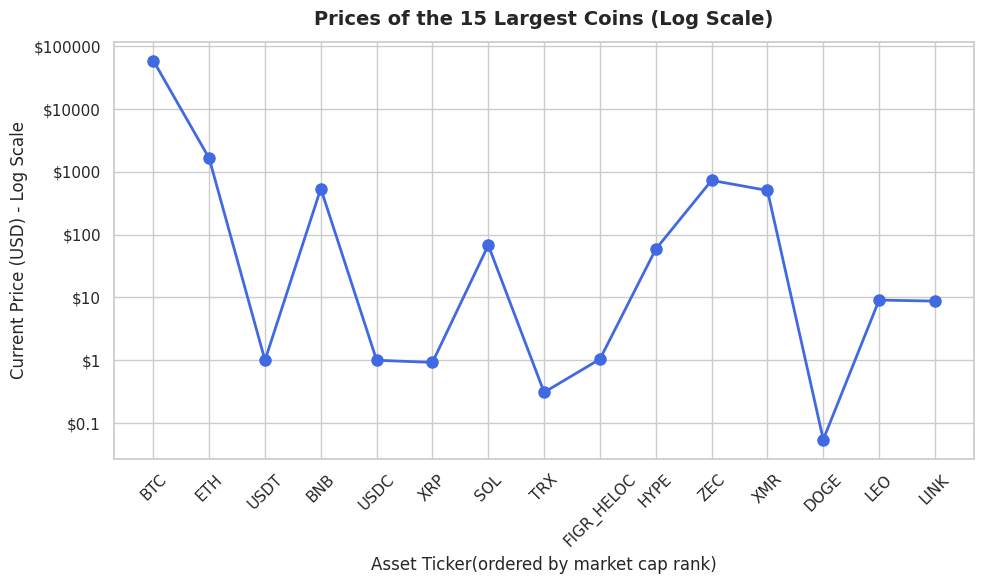

In [26]:
#keep only the 15 largest coins
df_top15= df_result.head(15)

# set the visual style
sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))

# create the line chart instead of the bar chart
# We add marker='o' to show clear points for each asset
plt.plot(
    df_top15['symbol'].str.upper(),
    df_top15['current_price'],
    marker='o',
    color='royalblue',
    linewidth=2,
    markersize=8
)

# Keep the y-axis on a logarithmic scale so all assets are clearly visible
plt.yscale('log')

# Add title and labels
plt.title("Prices of the 15 Largest Coins (Log Scale)", fontsize=14, fontweight='bold', pad=12)
plt.ylabel("Current Price (USD) - Log Scale", fontsize=12)
plt.xlabel("Asset Ticker(ordered by market cap rank)", fontsize=12)

# Customize the y-axis ticks to show actual dollar figures cleanly
plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('$%g'))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
query_concentration = """
WITH ranked AS (
    SELECT
        market_cap,
        total_volume,
        RANK() OVER (ORDER BY market_cap DESC)   AS cap_rank,
        RANK() OVER (ORDER BY total_volume DESC) AS volume_rank
    FROM crypto_market
)
SELECT
    ROUND(100.0 * SUM(CASE WHEN cap_rank <= 10 THEN market_cap END)
          / SUM(market_cap), 1) AS top10_market_cap_pct,
    ROUND(100.0 * SUM(CASE WHEN volume_rank <= 10 THEN total_volume END)
          / SUM(total_volume), 1) AS top10_volume_pct
FROM ranked;
"""

pd.read_sql(query_concentration, engine)

,top10_market_cap_pct,top10_volume_pct
0,89.6,92.0
